# 01b · Reichswald – índice de susceptibilidad a incendios forestales

Índice **estático y relativo** de *susceptibilidad* (no de riesgo: no incluye vulnerabilidad ni valor expuesto).

**Marco:** Chuvieco et al. (2010) combinan la *probabilidad de ignición* (sobre todo humana) con el *estado del combustible* (tipo + humedad). Aquí:

| Factor | Dato | Escala 0–1 |
|---|---|---|
| Tipo de combustible | DLR Tree Species Germany 2022 (10 m) | pino 1 · otras coníferas 0.6 · frondosas 0.3 · pérdida de cubierta 0.8 |
| Humedad del combustible | Anomalía de NDMI Sentinel-2 del verano `YEAR` vs. 2017–2025, **por píxel** (Yebra et al. 2013) | z = −2 → 1 · z = +2 → 0 |
| Ignición humana | Distancia a carreteras (OSM) y a zonas urbanas (WorldCover) | decaimiento exponencial |

**Excluidos y por qué:** pendiente (terreno casi llano, ver abajo), caminos forestales (están en todas partes, no discriminan), meteorología (es dinámica: para el peligro diario existe el Waldbrandgefahrenindex del DWD).

**Pesos:** iguales (supuesto) + análisis de sensibilidad. **Clases:** por cuantiles (top 20 % = alta).

In [1]:
import sys; sys.path.append("..")
import ee, numpy as np, pandas as pd, pyproj, rasterio
import matplotlib.pyplot as plt
from pathlib import Path
from rasterio.transform import array_bounds
from config import GEE_PROJECT, AOI_BBOX, CRS
from src import fire

ee.Initialize(project=GEE_PROJECT)

YEAR = 2025                    # verano evaluado (estado de humedad más reciente)
BASELINE = range(2017, 2026)   # referencia para la anomalía de NDMI
RES = 20                       # m
CACHE = Path("../data/processed/fire_inputs.npz")
fig_dir = Path("../site/projects/figures"); fig_dir.mkdir(parents=True, exist_ok=True)

aoi = ee.Geometry.Rectangle(AOI_BBOX)
reichswald = (ee.FeatureCollection("WCMC/WDPA/current/polygons").filterBounds(aoi)
              .filter(ee.Filter.stringContains("NAME", "Reichswald"))
              .geometry().intersection(aoi, 1))
transform, W, H = fire.make_grid(reichswald, CRS, RES)
print(W, "x", H, "celdas de", RES, "m")

C:\Users\ivana\miniforge3\envs\atlas\Lib\site-packages\google\api_core\_python_version_support.py:254: FutureWarning: You are using a Python version (3.11.18) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


1453 x 1596 celdas de 20 m


## 1. Insumos en una cuadrícula común (se guardan en caché porque la descarga tarda ~2 min)

In [2]:
if CACHE.exists():
    d = dict(np.load(CACHE))
else:
    inside = fire.ee_to_array(ee.Image(1).clip(reichswald), CRS, transform, W, H) == 1
    built = fire.ee_to_array(ee.Image(fire.WORLDCOVER).eq(50), CRS, transform, W, H) == 1
    z = fire.ee_to_array(fire.ndmi_zscore(reichswald, YEAR, BASELINE), CRS, transform, W, H)
    species = fire.tree_species_on_grid(CRS, transform, W, H)
    bbox = pyproj.Transformer.from_crs(CRS, "EPSG:4326", always_xy=True) \
                 .transform_bounds(*array_bounds(H, W, transform))
    hw = fire.osm_highways(bbox)
    roads = fire.lines_to_mask([g for g, h in hw if h not in fire.TRACKS], CRS, transform, W, H)
    tracks = fire.lines_to_mask([g for g, h in hw if h in fire.TRACKS], CRS, transform, W, H)
    d = dict(inside=inside, built=built, z=z, species=species, roads=roads, tracks=tracks)
    np.savez_compressed(CACHE, **d)

forest = d["inside"] & (d["species"] != fire.TREE_SPECIES_NODATA) & ~np.isnan(d["z"])
print(f"Bosque analizado: {forest.sum() * RES**2 / 1e6:.0f} km²")

names = {0: "Pine", 1: "Spruce", 2: "Douglas fir", 3: "Larch", 4: "Fir", 5: "Beech",
         6: "Oak", 7: "Birch", 8: "Alder", 9: "Other", 666: "Canopy cover loss"}
sp = pd.Series(d["species"][forest]).map(names).value_counts(normalize=True)
(sp * 100).round(1).rename("% del bosque")

Bosque analizado: 271 km²


Pine                 57.8
Other                10.4
Spruce                8.1
Larch                 6.5
Oak                   5.1
Beech                 3.3
Alder                 3.3
Canopy cover loss     2.5
Douglas fir           2.0
Birch                 1.0
Fir                   0.1
Name: % del bosque, dtype: float64

## 2. Comprobación de qué factores discriminan

In [3]:
d_road, d_track, d_built = (fire.distance_to(d[k], RES) for k in ("roads", "tracks", "built"))
dist = pd.DataFrame({"roads": d_road[forest], "forest tracks/paths": d_track[forest],
                     "built-up": d_built[forest]})
print("Distancia desde cada píxel de bosque (m):")
display(dist.quantile([0.1, 0.5, 0.9]).round(0))

slope = ee.Terrain.slope(ee.Image("USGS/SRTMGL1_003")).reduceRegion(
    ee.Reducer.percentile([50, 90, 99]), reichswald, 30, maxPixels=1e9).getInfo()
print("Pendiente (°):", {k: round(v, 1) for k, v in slope.items()})

Distancia desde cada píxel de bosque (m):


,roads,forest tracks/paths,built-up
0.1,60.0,0.0,100.0
0.5,342.0,40.0,449.0
0.9,1115.0,120.0,1252.0


Pendiente (°): {'slope_p50': 3.1, 'slope_p90': 7.3, 'slope_p99': 12.7}


- El 90 % del bosque está a < ~120 m de un camino forestal → ese factor no diferencia zonas, se excluye.
- Carreteras y zonas urbanas sí varían (cientos de metros a > 1 km) → se usan.
- Pendiente mediana ~3°, p90 ~7° → terreno casi llano, la topografía apenas modula la propagación aquí → se excluye.

## 3. Factores e índice

In [4]:
D_ROAD, D_BUILT = 300, 500   # m: distancia a la que la influencia cae al 37 % (supuesto, ver sensibilidad)

def factors(d_road0=D_ROAD, d_built0=D_BUILT):
    return {"fuel": fire.fuel_score(d["species"]),
            "moisture": np.clip((2 - d["z"]) / 4, 0, 1),     # z = -2 → 1 (muy seco), z = +2 → 0
            "human": (fire.decay(d_road, d_road0) + fire.decay(d_built, d_built0)) / 2}

F = factors()
W_BASE = {"fuel": 1, "moisture": 1, "human": 1}
index = np.where(forest, fire.susceptibility(F, W_BASE), np.nan)
classes = fire.quantile_classes(index, forest)

summary = pd.DataFrame({k: v[forest] for k, v in F.items()}).quantile([0.1, 0.5, 0.9]).round(2)
display(summary)
pine_high = (d["species"][classes == 3] == 0).mean()
print(f"Pino: {(d['species'][forest] == 0).mean():.0%} del bosque, {pine_high:.0%} de la clase alta")

,fuel,moisture,human
0.1,0.3,0.16,0.07
0.5,1.0,0.38,0.37
0.9,1.0,0.71,0.80


Pino: 58% del bosque, 92% de la clase alta


## 4. Sensibilidad: ¿cambian las zonas altas si cambio pesos o distancias?

In [5]:
high = classes == 3
tests = {"fuel ×2":     (F, {"fuel": 2, "moisture": 1, "human": 1}),
         "moisture ×2": (F, {"fuel": 1, "moisture": 2, "human": 1}),
         "human ×2":    (F, {"fuel": 1, "moisture": 1, "human": 2}),
         "distances ÷2": (factors(D_ROAD / 2, D_BUILT / 2), W_BASE),
         "distances ×2": (factors(D_ROAD * 2, D_BUILT * 2), W_BASE)}
rows = []
for name, (f, w) in tests.items():
    s = fire.susceptibility(f, w)
    h = fire.quantile_classes(s, forest) == 3
    rows.append({"variant": name,
                 "Spearman ρ vs base": round(fire.rank_correlation(index[forest], s[forest]), 2),
                 "% of high class kept": round(100 * (h & high).sum() / high.sum())})
sens = pd.DataFrame(rows); sens.to_csv("../data/processed/fire_sensitivity.csv", index=False); sens

,variant,Spearman ρ vs base,% of high class kept
0,fuel ×2,0.95,94
1,moisture ×2,0.96,81
2,human ×2,0.91,81
3,distances ÷2,0.99,92
4,distances ×2,0.99,92


## 5. Mapa estático (web, LinkedIn, PDF)

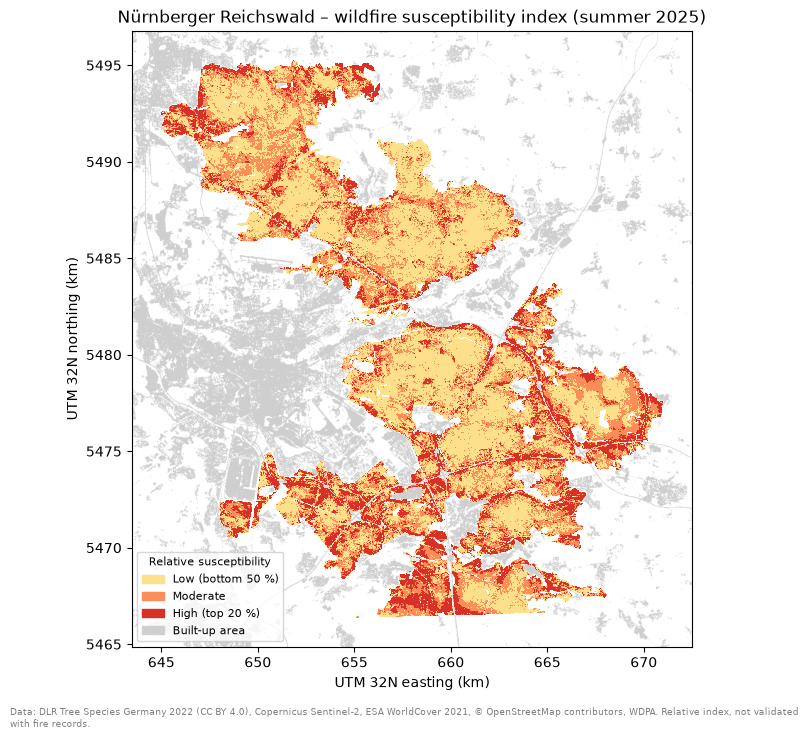

In [6]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

COLORS = ["#fee08b", "#fc8d59", "#d73027"]          # low, moderate, high
LABELS = ["Low (bottom 50 %)", "Moderate", "High (top 20 %)"]
west, south, east, north = array_bounds(H, W, transform)
ext = [west / 1e3, east / 1e3, south / 1e3, north / 1e3]

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(np.where(d["built"], 1, np.nan), extent=ext, cmap=ListedColormap(["#cfcfcf"]))
ax.imshow(np.where(classes > 0, classes, np.nan), extent=ext,
          cmap=ListedColormap(COLORS), vmin=0.5, vmax=3.5, interpolation="nearest")
ax.legend(handles=[Patch(color=c, label=l) for c, l in zip(COLORS, LABELS)]
                  + [Patch(color="#cfcfcf", label="Built-up area")],
          loc="lower left", fontsize=8, frameon=True, title="Relative susceptibility", title_fontsize=8)
ax.set(title=f"Nürnberger Reichswald – wildfire susceptibility index (summer {YEAR})",
       xlabel="UTM 32N easting (km)", ylabel="UTM 32N northing (km)")
fig.text(0.01, 0.01, "Data: DLR Tree Species Germany 2022 (CC BY 4.0), Copernicus Sentinel-2, "
         "ESA WorldCover 2021, © OpenStreetMap contributors, WDPA. Relative index, not validated "
         "with fire records.", fontsize=6.5, color="grey", wrap=True)
fig.savefig(fig_dir / "reichswald_fire_susceptibility.png", dpi=200, bbox_inches="tight")

## 6. Mapa interactivo (web) y GeoTIFF del índice


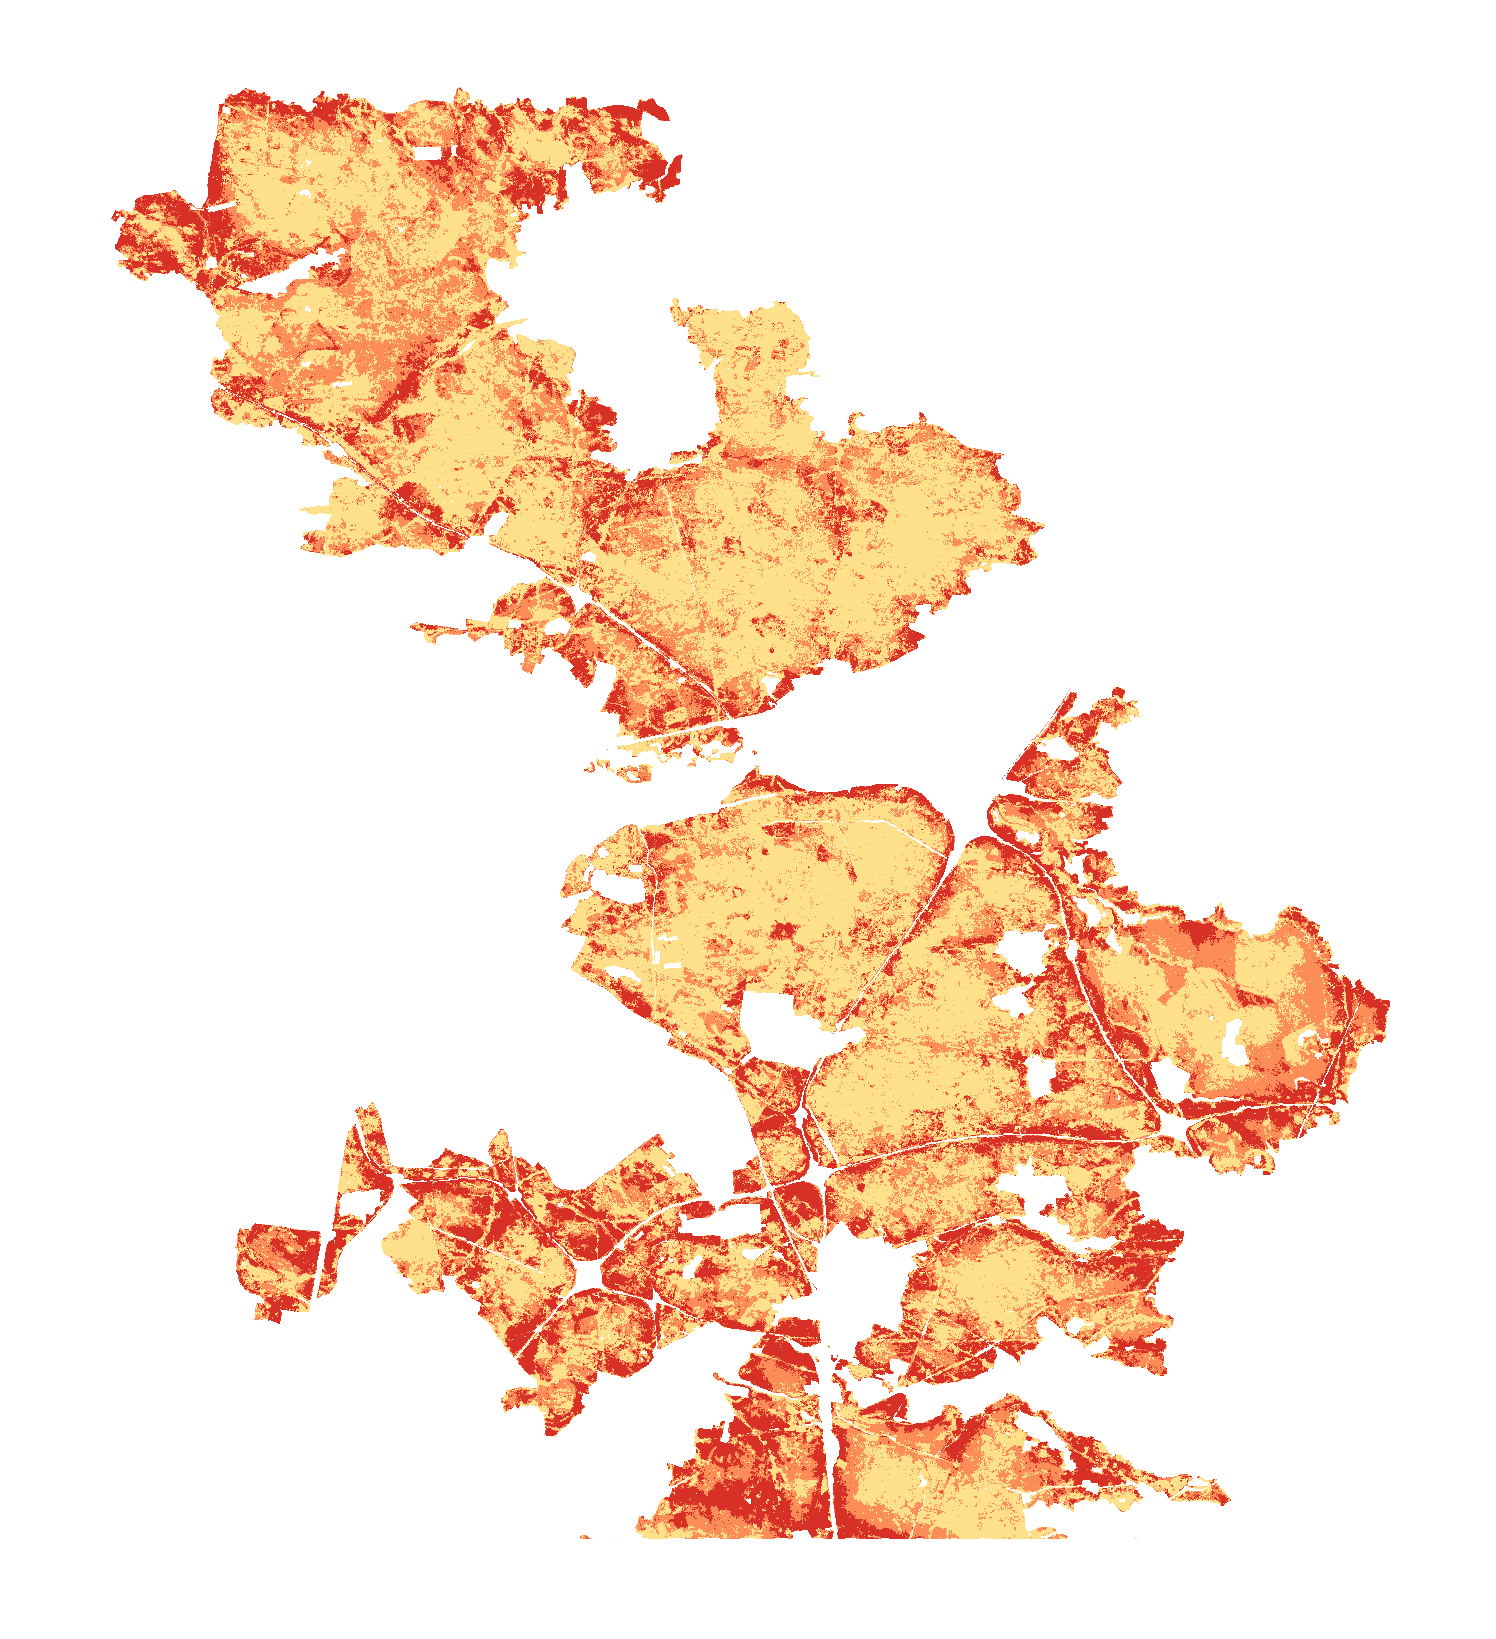

In [7]:
from src import webmap
from rasterio.warp import calculate_default_transform, reproject, Resampling

# GeoTIFF para reproducibilidad
profile = dict(driver="GTiff", height=H, width=W, count=2, dtype="float32", crs=CRS,
               transform=transform, nodata=np.nan, compress="deflate")
with rasterio.open("../data/processed/reichswald_fire_susceptibility.tif", "w", **profile) as dst:
    dst.write(index.astype("float32"), 1); dst.write(classes.astype("float32"), 2)
    dst.set_band_description(1, "index"); dst.set_band_description(2, "class")

# Clases → RGBA en Web Mercator para superponer en el mapa web
t3857, w3857, h3857 = calculate_default_transform(CRS, "EPSG:3857", W, H, *array_bounds(H, W, transform))
cls3857 = np.zeros((h3857, w3857), "uint8")
reproject(classes, cls3857, src_transform=transform, src_crs=CRS, dst_transform=t3857,
          dst_crs="EPSG:3857", resampling=Resampling.nearest)
rgba = np.zeros((*cls3857.shape, 4))
for c, hexcol in enumerate(COLORS, start=1):
    rgba[cls3857 == c] = [*(int(hexcol[i:i + 2], 16) / 255 for i in (1, 3, 5)), 1]
png = fig_dir / "reichswald_fire_web.png"
plt.imsave(png, rgba)

lon0, lat0, lon1, lat1 = pyproj.Transformer.from_crs("EPSG:3857", "EPSG:4326", always_xy=True) \
    .transform_bounds(*array_bounds(h3857, w3857, t3857))
bounds = [[lat0, lon0], [lat1, lon1]]
webmap.overlay_map(png, bounds, "Wildfire susceptibility",
                   webmap.class_legend("Relative wildfire susceptibility", COLORS[::-1],
                                       ["High (top 20 %)", "Moderate", "Low (bottom 50 %)"]),
                   fig_dir / "reichswald_fire_map.html", opacity=0.75)